# 1일차 EDA — 바이어 연체 분포

- 원본: `data/day1/d1_buyers_raw.xlsx` (읽기만) · 결제방식 코드표: `workbench/day1/outputs/d1_code_table.csv`
- 정리 규칙과 코드: `scripts/d1_eda_prep.py` (진단 근거: `workbench/day1/outputs/d1_quality_report.md`)
- 연체 바이어 = `max_dpd_days > 0`. 연체율 = 연체 바이어 수 ÷ 연체일을 판정할 수 있는 바이어 수
- 마무리: 커널 재시작 후 전체 실행

In [1]:
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from matplotlib import font_manager

# 경로는 저장소 맨 위 폴더 기준 — pyproject.toml이 있는 곳까지 올라간다
root = Path.cwd()
while not (root / "pyproject.toml").exists():
    root = root.parent
os.chdir(root)
sys.path.insert(0, str(root / "scripts"))
from d1_eda_prep import load_analysis_table

# 한글 글꼴 · 차트 기본값
FONT = "tools/fonts/NanumGothic-Regular.ttf"
font_manager.fontManager.addfont(FONT)
plt.rcParams.update({
    # 나눔고딕에 없는 글자(예: Türkiye의 ü)는 DejaVu Sans로 채운다
    "font.family": [font_manager.FontProperties(fname=FONT).get_name(), "DejaVu Sans"],
    "axes.unicode_minus": False,
    "figure.dpi": 110, "savefig.dpi": 150,
    "axes.spines.top": False, "axes.spines.right": False,
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "text.color": "#0b0b0b", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
})
BAR = "#2a78d6"
CHARTS = Path("workbench/day1/outputs/charts")
NOTES = Path("workbench/day1/outputs/d1_eda_notes.md")

df, log = load_analysis_table()
for k, v in log.items():
    print(f"{k}: {v}")

judged = df[df["is_overdue"].notna()]  # 연체율 분모: 연체일 판정 가능 바이어
print(f"\n바이어 {len(df)}곳 · 연체일 판정 가능 {len(judged)}곳 · 연체 바이어 {int(judged['is_overdue'].sum())}곳")
df[["buyer_id", "country_code", "country_name", "payment_terms_raw", "payment_method",
    "max_dpd_days_raw", "max_dpd_days", "is_overdue"]].head()

원본 행: 153
중복 제거 후 행: 150
제거된 중복 buyer_id: ['B047', 'B094', 'B114']
연체일 판정 불가: [['B058', '-'], ['B066', '확인중']]
연체일 단위 제거: [['B048', '90일'], ['B147', '381 days']]
결제방식 검토 필요·미분류: [['B085', '10% T/T advance + 90% O/A 90 days', '검토 필요']]

바이어 150곳 · 연체일 판정 가능 148곳 · 연체 바이어 25곳


,buyer_id,country_code,country_name,payment_terms_raw,payment_method,max_dpd_days_raw,max_dpd_days,is_overdue
0,B001,NLD,Netherlands,T/T 90 DAYS AFTER B/L,OA,0,0.0,False
1,B002,CHN,China,OA90,OA,0,0.0,False
2,B003,IDN,Indonesia,D/A 90,DA,0,0.0,False
3,B004,EGY,Egypt,Confirmed L/C at sight,LC_SIGHT,0,0.0,False
4,B005,VNM,Vietnam,T/T 90 days after B/L,OA,13,13.0,True


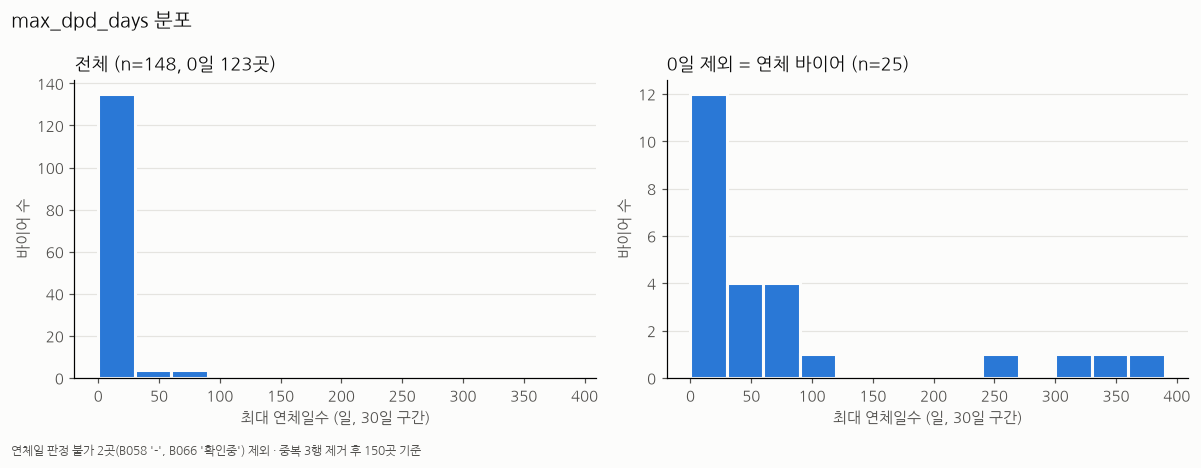

0일 제외 요약: {'count': 25.0, 'mean': 81.0, 'std': 114.0, 'min': 3.0, '25%': 15.0, '50%': 31.0, '75%': 74.0, 'max': 381.0}
구간별(0일 제외): {Interval(0, 30, closed='left'): 12, Interval(30, 60, closed='left'): 4, Interval(60, 90, closed='left'): 4, Interval(90, 180, closed='left'): 1, Interval(180, 10000, closed='left'): 4}
180일 초과: [['B044', 355.0], ['B071', 269.0], ['B083', 305.0], ['B147', 381.0]]


In [2]:
# 차트 1: max_dpd_days 분포 — 전체 / 0일 제외
dpd = judged["max_dpd_days"]
pos = dpd[dpd > 0]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
bins = range(0, int(dpd.max()) + 31, 30)
axes[0].hist(dpd, bins=bins, color=BAR, edgecolor="#fcfcfb", linewidth=2)
axes[0].set_title(f"전체 (n={len(dpd)}, 0일 {int((dpd == 0).sum())}곳)", loc="left")
axes[1].hist(pos, bins=bins, color=BAR, edgecolor="#fcfcfb", linewidth=2)
axes[1].set_title(f"0일 제외 = 연체 바이어 (n={len(pos)})", loc="left")
for ax in axes:
    ax.set_xlabel("최대 연체일수 (일, 30일 구간)")
    ax.set_ylabel("바이어 수")
    ax.grid(axis="y", color="#e5e4e0", linewidth=0.8)
    ax.set_axisbelow(True)
fig.suptitle("max_dpd_days 분포", x=0.01, ha="left", fontsize=13)
fig.text(0.01, -0.03, f"연체일 판정 불가 {len(df) - len(judged)}곳(B058 '-', B066 '확인중') 제외 · 중복 3행 제거 후 150곳 기준",
         fontsize=8, color="#52514e")
fig.tight_layout()
fig.savefig(CHARTS / "d1_dpd_hist.png", bbox_inches="tight")
plt.show()

print("0일 제외 요약:", pos.describe().round(1).to_dict())
# 히스토그램과 같은 왼쪽 닫힘 구간 [a, b)
print("구간별(0일 제외):", pd.cut(pos, [0, 30, 60, 90, 180, 10_000], right=False).value_counts(sort=False).to_dict())
print("180일 초과:", judged.loc[judged["max_dpd_days"] > 180, ["buyer_id", "max_dpd_days"]].values.tolist())

**차트 1 해석** (`outputs/charts/d1_dpd_hist.png`)

1. 연체일을 판정할 수 있는 148곳 중 123곳이 0일이라, 전체 그림은 0~30일 막대 하나에 몰려 있습니다. 연체 바이어 25곳의 모양은 0일을 뺀 그림에서만 보입니다.
2. 연체 바이어 25곳 중 12곳이 30일 미만이고 중앙값은 31일로, 절반 가까이가 짧은 지연입니다.
3. 180일을 넘는 4곳(B044 355일 · B071 269일 · B083 305일 · B147 381일)이 평균을 81일로 끌어올립니다. 90~180일 구간은 1곳(B048 90일)뿐이라, 장기 연체는 따로 떨어진 무리로 봐야 합니다.

country_code         country_name  바이어수  연체       비율
         MEX               Mexico     6   4 0.666667
         THA             Thailand     5   2 0.400000
         TWN               Taiwan     5   2 0.400000
         ARE United Arab Emirates     6   2 0.333333
         IDN            Indonesia     7   2 0.285714
         TUR              Türkiye     7   2 0.285714
         BRA               Brazil     4   1 0.250000
         USA        United States    18   4 0.222222
         DEU              Germany    12   2 0.166667
         POL               Poland     6   1 0.166667
         IND                India    10   1 0.100000
         VNM              Vietnam    12   1 0.083333
         CHN                China    14   1 0.071429
         JPN                Japan    10   0 0.000000
         GBR       United Kingdom     6   0 0.000000
         NLD          Netherlands     5   0 0.000000
         SAU         Saudi Arabia     5   0 0.000000
         EGY                Egypt     4   0 0.

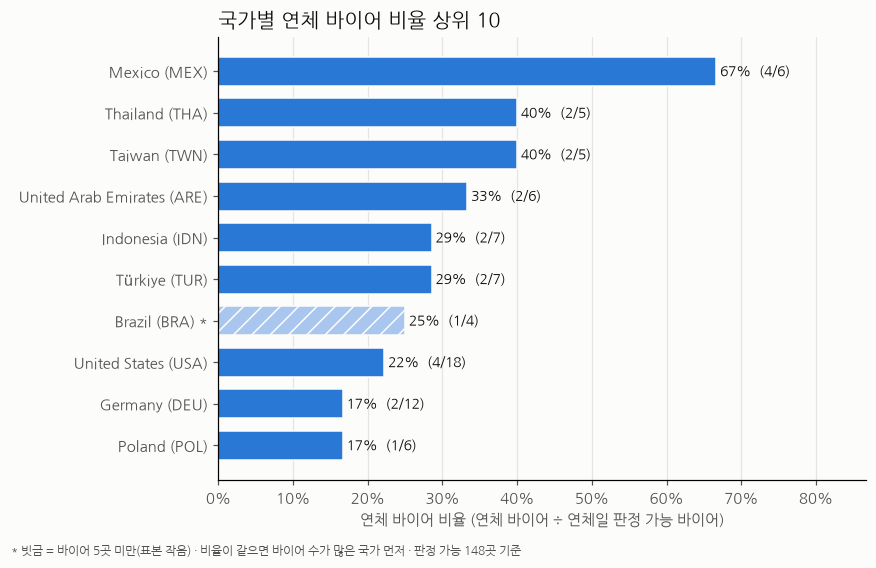

In [3]:
# 차트 2: 국가별 연체 바이어 비율 상위 10 (바이어 5곳 미만 국가는 빗금 + *)
SMALL_N = 5


def overdue_rate(by):
    g = judged.groupby(by).agg(바이어수=("buyer_id", "size"), 연체=("is_overdue", "sum"))
    g["연체"] = g["연체"].astype(int)
    g["비율"] = g["연체"] / g["바이어수"]
    return g


by_country = overdue_rate(["country_code", "country_name"]).reset_index()
top10 = by_country.sort_values(["비율", "바이어수"], ascending=[False, False]).head(10)
print(by_country.sort_values(["비율", "바이어수"], ascending=[False, False]).to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 5))
plot = top10.iloc[::-1]
small = plot["바이어수"] < SMALL_N
labels = [f"{r.country_name} ({r.country_code}){' *' if r.바이어수 < SMALL_N else ''}" for r in plot.itertuples()]
bars = ax.barh(labels, plot["비율"], color=[("#a9c7ee" if s else BAR) for s in small],
               hatch=["//" if s else "" for s in small], edgecolor="#fcfcfb", height=0.7)
for b, r in zip(bars, plot.itertuples()):
    ax.text(b.get_width() + 0.005, b.get_y() + b.get_height() / 2,
            f"{r.비율:.0%}  ({r.연체}/{r.바이어수})", va="center", fontsize=9, color="#0b0b0b")
ax.set_xlim(0, plot["비율"].max() * 1.3)
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.set_xlabel("연체 바이어 비율 (연체 바이어 ÷ 연체일 판정 가능 바이어)")
ax.grid(axis="x", color="#e5e4e0", linewidth=0.8)
ax.set_axisbelow(True)
ax.set_title("국가별 연체 바이어 비율 상위 10", loc="left", fontsize=13)
fig.text(0.01, -0.02, f"* 빗금 = 바이어 {SMALL_N}곳 미만(표본 작음) · 비율이 같으면 바이어 수가 많은 국가 먼저 · 판정 가능 {len(judged)}곳 기준",
         fontsize=8, color="#52514e")
fig.tight_layout()
fig.savefig(CHARTS / "d1_country_overdue_top10.png", bbox_inches="tight")
plt.show()

**차트 2 해석** (`outputs/charts/d1_country_overdue_top10.png`)

1. 멕시코가 67%(4/6)로 가장 높고, 2위인 태국 · 대만(각 40%, 2/5)과도 차이가 큽니다.
2. 바이어가 가장 많은 미국은 22%(4/18)로 8위지만, 연체 바이어 수는 멕시코와 같은 4곳입니다. 비율 순위와 건수 순위는 다릅니다.
3. 상위 10개 중 바이어 5곳 미만 국가는 브라질(1/4) 하나입니다. 나머지도 대부분 5~7곳이라 1곳 차이로 비율이 14~20%p씩 움직이므로(1/7 ≈ 14%p, 1/5 = 20%p) 순위는 참고로만 봅니다.

                전체 바이어  바이어수  연체        비율
결제방식                                      
TT_ADV              12    12   0  0.000000
TT_SPLIT_30_70       8     8   1  0.125000
LC_SIGHT            10    10   0  0.000000
LC_USANCE            4     4   0  0.000000
DP                   4     4   0  0.000000
DA                  24    23   5  0.217391
OA                  87    86  18  0.209302
검토 필요                1     1   1  1.000000
합계: {'전체 바이어': 150, '바이어수': 148, '연체': 25}


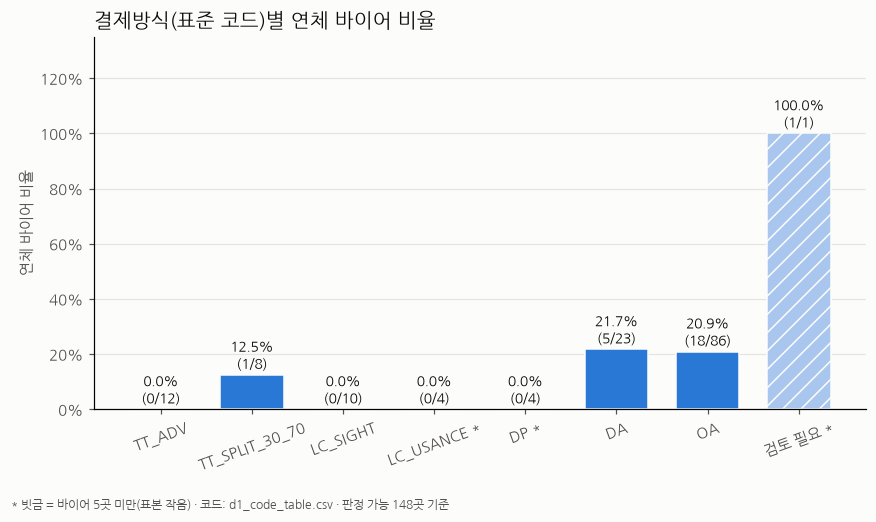

In [4]:
# 차트 3: 결제방식(표준 코드)별 연체 바이어 비율 — 코드 순서 고정, 바이어 5곳 미만은 빗금 + *
METHOD_ORDER = ["TT_ADV", "TT_SPLIT_30_70", "LC_SIGHT", "LC_USANCE", "DP", "DA", "OA", "검토 필요", "미분류"]

by_method = overdue_rate("payment_method")
by_method.insert(0, "전체 바이어", df["payment_method"].value_counts())
by_method = by_method.reindex([m for m in METHOD_ORDER if m in by_method.index])
by_method.index.name = "결제방식"
print(by_method.to_string())
print("합계:", by_method[["전체 바이어", "바이어수", "연체"]].sum().to_dict())

fig, ax = plt.subplots(figsize=(8, 4.5))
small = by_method["바이어수"] < SMALL_N
labels = [f"{m}{' *' if s else ''}" for m, s in zip(by_method.index, small)]
bars = ax.bar(labels, by_method["비율"], color=[("#a9c7ee" if s else BAR) for s in small],
              hatch=["//" if s else "" for s in small], edgecolor="#fcfcfb", width=0.7)
for b, r in zip(bars, by_method.itertuples()):
    # 소수 첫째 자리까지 (1/8 = 12.5%가 12%로 보이지 않게)
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.008,
            f"{r.비율:.1%}\n({r.연체}/{r.바이어수})", ha="center", va="bottom", fontsize=9, color="#0b0b0b")
ax.set_ylim(0, max(by_method["비율"].max() * 1.35, 0.1))
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.set_ylabel("연체 바이어 비율")
ax.tick_params(axis="x", labelrotation=20)
ax.grid(axis="y", color="#e5e4e0", linewidth=0.8)
ax.set_axisbelow(True)
ax.set_title("결제방식(표준 코드)별 연체 바이어 비율", loc="left", fontsize=13)
fig.text(0.01, -0.04, f"* 빗금 = 바이어 {SMALL_N}곳 미만(표본 작음) · 코드: d1_code_table.csv · 판정 가능 {len(judged)}곳 기준",
         fontsize=8, color="#52514e")
fig.tight_layout()
fig.savefig(CHARTS / "d1_paymethod_overdue.png", bbox_inches="tight")
plt.show()

**차트 3 해석** (`outputs/charts/d1_paymethod_overdue.png`)

1. 연체 바이어 25곳 중 23곳이 DA(21.7%, 5/23)와 OA(20.9%, 18/86)에 있고, TT_ADV(0/12)와 LC_SIGHT(0/10)에는 연체 바이어가 없습니다.
2. TT_SPLIT_30_70은 12.5%(1/8, B087 32일)입니다. 사람 판단으로 TT_ADV에 넣은 `TT`/`tt` 4곳(B010 · B036 · B038 · B060)은 모두 연체일 0일이라, 이 판단은 TT_ADV 비율 0%를 바꾸지 않습니다.
3. LC_USANCE(0/4) · DP(0/4) · 검토 필요(1/1, B085)는 바이어 5곳 미만이라 표본 작음 — 결론 보류입니다. LC_USANCE 4곳 중 2곳(B057 · B081)은 코드표 확신이 '낮음'인 표기(`L/C 90 days` · `L/C 60 days`)입니다.

In [5]:
# d1_eda_notes.md 쓰기 — 해석은 이 노트북의 '**차트 N 해석**' 마크다운 셀을 그대로 옮긴다(노트북을 저장한 뒤 실행)
import json

NB = Path("workbench/day1/notebooks/d1_eda.ipynb")
KEEP = "## 손 검산"  # 이 제목부터 끝까지는 사람이 쓴 절 — 다시 실행해도 그대로 남긴다

cells = json.loads(NB.read_text(encoding="utf-8"))["cells"]
interp = ["".join(c["source"]) for c in cells
          if c["cell_type"] == "markdown" and "".join(c["source"]).startswith("**차트")]
assert len(interp) == 3, f"해석 셀이 3개가 아님: {len(interp)}"

kept = ""
if NOTES.exists():
    old = NOTES.read_text(encoding="utf-8")
    if KEEP in old:
        kept = old[old.index(KEEP):]

rows = ["| 결제방식 | 바이어 수 | 연체일 판정 가능 | 연체 바이어 수 | 연체 바이어 비율 | 비고 |",
        "|---|---|---|---|---|---|"]
for r in by_method.itertuples():  # itertuples는 열마다 정수형을 유지한다(iterrows는 실수로 바뀜)
    note = "표본 작음 — 결론 보류" if r.바이어수 < SMALL_N else ""
    rows.append(f"| {r.Index} | {r._1} | {r.바이어수} | {r.연체} | {r.비율:.1%} | {note} |")
tot = by_method[["전체 바이어", "바이어수", "연체"]].sum()
rows.append(f"| 합계 | {tot['전체 바이어']} | {tot['바이어수']} | {tot['연체']} | {tot['연체'] / tot['바이어수']:.1%} | |")

text = f"""# 1일차 EDA 노트 — 바이어 연체 분포

- 노트북: `workbench/day1/notebooks/d1_eda.ipynb` · 정리 규칙과 코드: `scripts/d1_eda_prep.py`
- 원본: `data/day1/d1_buyers_raw.xlsx` (읽기만) · 결제방식 코드: `workbench/day1/outputs/d1_code_table.csv`
- 기준: 중복 3행(B047 · B094 · B114) 제거 후 {len(df)}곳. 연체일 판정 불가 {len(df) - len(judged)}곳(B058 `-` · B066 `확인중`)은 비율 분모에서 뺌
- 연체 바이어 = `max_dpd_days > 0` · 연체 바이어 비율 = 연체 바이어 수 ÷ 연체일 판정 가능 바이어 수
- 차트: `workbench/day1/outputs/charts/` (d1_dpd_hist.png · d1_country_overdue_top10.png · d1_paymethod_overdue.png)

## 차트 해석

{chr(10).join(s + chr(10) for s in interp)}
## 결제방식별 연체 바이어

{chr(10).join(rows)}

- 바이어 수 = 중복 제거 후 그 결제방식의 바이어 수. 연체일 판정 가능 = 그중 연체일이 숫자인 바이어 수(비율의 분모)
- DA · OA는 바이어 수와 판정 가능 수가 1곳씩 다름: DA는 B066(`확인중`), OA는 B058(`-`) — 연체일 판정 불가
- '검토 필요' = 코드표에서 표준 코드 7개 어디에도 맞지 않는 표기(B085 `10% T/T advance + 90% O/A 90 days`)
- 비율은 소수 첫째 자리 반올림. 계산 코드: 노트북 '차트 3' 셀의 `overdue_rate("payment_method")`
"""
if kept:
    text = text.rstrip("\n") + "\n\n" + kept
NOTES.write_text(text, encoding="utf-8")
print(f"{NOTES} 저장 · 손 검산 절 {'유지' if kept else '없음'}")
print(text)

workbench\day1\outputs\d1_eda_notes.md 저장 · 손 검산 절 없음
# 1일차 EDA 노트 — 바이어 연체 분포

- 노트북: `workbench/day1/notebooks/d1_eda.ipynb` · 정리 규칙과 코드: `scripts/d1_eda_prep.py`
- 원본: `data/day1/d1_buyers_raw.xlsx` (읽기만) · 결제방식 코드: `workbench/day1/outputs/d1_code_table.csv`
- 기준: 중복 3행(B047 · B094 · B114) 제거 후 150곳. 연체일 판정 불가 2곳(B058 `-` · B066 `확인중`)은 비율 분모에서 뺌
- 연체 바이어 = `max_dpd_days > 0` · 연체 바이어 비율 = 연체 바이어 수 ÷ 연체일 판정 가능 바이어 수
- 차트: `workbench/day1/outputs/charts/` (d1_dpd_hist.png · d1_country_overdue_top10.png · d1_paymethod_overdue.png)

## 차트 해석

**차트 1 해석** (`outputs/charts/d1_dpd_hist.png`)

1. 연체일을 판정할 수 있는 148곳 중 123곳이 0일이라, 전체 그림은 0~30일 막대 하나에 몰려 있습니다. 연체 바이어 25곳의 모양은 0일을 뺀 그림에서만 보입니다.
2. 연체 바이어 25곳 중 12곳이 30일 미만이고 중앙값은 31일로, 절반 가까이가 짧은 지연입니다.
3. 180일을 넘는 4곳(B044 355일 · B071 269일 · B083 305일 · B147 381일)이 평균을 81일로 끌어올립니다. 90~180일 구간은 1곳(B048 90일)뿐이라, 장기 연체는 따로 떨어진 무리로 봐야 합니다.

**차트 2 해석** (`outputs/charts/d1_country_overdue_top10.png`)

1. 멕시코가 67%(4/6)로 가장 높고, 2위인 태국 · 대만(각 40%, 2/5)